# SAE 5.03 – MNIST
## Partie 6 : détection d'anomalies

Sur MNIST, une « anomalie » peut être de deux natures :

| Type | Exemple | Méthodes |
|---|---|---|
| **Image atypique** au sein de sa classe | 7 barré, 2 très incliné, trait très épais, chiffre tronqué | univariée (encre, z-score robuste) ; multivariées non supervisées par classe : erreur de reconstruction ACP, Isolation Forest, LOF |
| **Étiquette probablement erronée** | un 4 étiqueté 9 | supervisée : probabilités KNN obtenues en validation croisée (logique du *confident learning*, Northcutt *et al.*, 2021) |

Les détections sont faites **sur le jeu d'apprentissage uniquement** : le jeu de test n'est jamais modifié, pour rester comparable à la littérature.
On décide ensuite de modifier, ou non, le jeu de données.

Sorties : `figures/fig6_*.png`, `resultats/t6_*.csv`, `resultats/chiffres_cles_p6.json`.

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIG, RES = ROOT / "data", ROOT / "figures", ROOT / "resultats"
sys.path.insert(0, str(ROOT / "scripts"))
from mnist_io import charger_mnist

SEED = 42
TAUX = 0.01          # part d'images signalées par chaque méthode multivariée (1 %)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
CH = {}

def savefig(nom):
    plt.savefig(FIG / f"{nom}.png", bbox_inches="tight", facecolor="white")

def pct(x, nd=2):
    return round(100 * float(x), nd)

X_train, y_train, X_test, y_test = charger_mnist(DATA)
X = X_train.reshape(len(X_train), -1).astype(np.float32) / 255
const = X.var(axis=0) == 0
Xu = X[:, ~const]                       # 717 pixels utiles (cf. partie 4)
encre = X.sum(axis=1)                   # quantité d'encre (pixels « pleins »)
print(X.shape, Xu.shape)

(60000, 784) (60000, 717)


## 6.1 Approche univariée : quantité d'encre (z-score robuste)

Pour chaque classe, on calcule le **z-score robuste** de la quantité d'encre (Iglewicz & Hoaglin, 1993) :
$z_i = 0{,}6745\,(x_i - \mathrm{médiane}) / \mathrm{MAD}$. Une image est signalée si $|z_i| > 3{,}5$.
Calculé par classe, il ne pénalise pas le 1 (naturellement peu encré) ni le 0 (très encré).

In [2]:
z = np.zeros(len(X))
for c in range(10):
    m = y_train == c
    med = np.median(encre[m]); mad = np.median(np.abs(encre[m] - med))
    z[m] = 0.6745 * (encre[m] - med) / mad
flag_uni = np.abs(z) > 3.5

uni = pd.DataFrame({"classe": y_train, "haut": z > 3.5, "bas": z < -3.5}).groupby("classe").mean() * 100
CH.update({"uni_pct": pct(flag_uni.mean()), "uni_n": int(flag_uni.sum()),
           "uni_haut_pct": pct((z > 3.5).mean()), "uni_bas_pct": pct((z < -3.5).mean()),
           "uni_classe_max": int(uni.sum(1).idxmax()), "uni_classe_max_pct": round(float(uni.sum(1).max()), 2)})
print(f"{flag_uni.sum()} images signalées ({pct(flag_uni.mean())} %), dont {(z > 3.5).sum()} trop encrées")
uni.round(2)

191 images signalées (0.32 %), dont 191 trop encrées


C:\Users\amavi\AppData\Local\Temp\ipykernel_27752\775773970.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  "uni_classe_max": int(uni.sum(1).idxmax()), "uni_classe_max_pct": round(float(uni.sum(1).max()), 2)})
C:\Users\amavi\AppData\Local\Temp\ipykernel_27752\775773970.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  "uni_classe_max": int(uni.sum(1).idxmax()), "uni_classe_max_pct": round(float(uni.sum(1).max()), 2)})


,haut,bas
classe,,
0,0.14,0.0
1,0.59,0.0
2,0.12,0.0
3,0.15,0.0
4,0.27,0.0
5,0.31,0.0
6,0.29,0.0
7,0.26,0.0
8,0.36,0.0


## 6.2 Approches multivariées non supervisées, classe par classe

On travaille dans l'espace des **50 premières composantes principales** (≈ 82 % de la variance, cf. partie 5) pour réduire le bruit et le coût de calcul.
Pour chaque classe (≈ 6 000 images), trois méthodes de principes différents attribuent un score d'anomalie ; chacune signale les 1 % d'images les plus anormales :

1. **Erreur de reconstruction ACP** : une ACP à 20 composantes est ajustée sur la classe ; une image mal reconstruite s'écarte des « formes typiques » de sa classe ;
2. **Isolation Forest** (Liu *et al.*, 2008) : une image isolée en peu de coupures aléatoires est anormale ;
3. **Local Outlier Factor** (Breunig *et al.*, 2000) : une image située dans une zone de densité plus faible que ses 20 voisins est anormale.

On retient comme **anomalie forte** une image signalée par **au moins 2 méthodes sur 3** (consensus).

In [3]:
pca50 = PCA(50, random_state=SEED).fit(Xu)
Z = pca50.transform(Xu)
CH["pca50_var_pct"] = round(100 * float(pca50.explained_variance_ratio_.sum()), 1)

score = {k: np.zeros(len(X)) for k in ("reconstruction", "iforest", "lof")}
t0 = time.time()
for c in range(10):
    m = np.flatnonzero(y_train == c)
    # 1. erreur de reconstruction (ACP à 20 composantes propre à la classe)
    p = PCA(20, random_state=SEED).fit(Xu[m])
    rec = p.inverse_transform(p.transform(Xu[m]))
    score["reconstruction"][m] = ((Xu[m] - rec) ** 2).sum(axis=1)
    # 2. Isolation Forest (score_samples : plus petit = plus anormal -> on prend l'opposé)
    iso = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Z[m])
    score["iforest"][m] = -iso.score_samples(Z[m])
    # 3. LOF
    lof = LocalOutlierFactor(n_neighbors=20, n_jobs=-1).fit(Z[m])
    score["lof"][m] = -lof.negative_outlier_factor_
print(f"scores calculés en {time.time() - t0:.0f} s")

# seuil : les 1 % d'images les plus anormales de chaque classe, pour chaque méthode
flags = {}
for k, s in score.items():
    f = np.zeros(len(X), bool)
    for c in range(10):
        m = np.flatnonzero(y_train == c)
        f[m] = s[m] >= np.quantile(s[m], 1 - TAUX)
    flags[k] = f
F = pd.DataFrame(flags)
F["univarie"] = flag_uni
nb_methodes = F[["reconstruction", "iforest", "lof"]].sum(axis=1).values
forte = nb_methodes >= 2

# score agrégé = moyenne des rangs centiles intra-classe (pour classer les images)
rang = pd.DataFrame({k: pd.Series(s).groupby(y_train).rank(pct=True) for k, s in score.items()})
score_global = rang.mean(axis=1).values

# accord entre méthodes (indice de Jaccard)
meth = ["reconstruction", "iforest", "lof", "univarie"]
jac = pd.DataFrame([[ (F[a] & F[b]).sum() / max((F[a] | F[b]).sum(), 1) for b in meth] for a in meth],
                   index=meth, columns=meth).round(2)
CH.update({
    "consensus_n": int(forte.sum()), "consensus_pct": pct(forte.mean()),
    "trois_methodes_n": int((nb_methodes == 3).sum()),
    "jaccard_rec_iso": float(jac.loc["reconstruction", "iforest"]),
    "jaccard_rec_lof": float(jac.loc["reconstruction", "lof"]),
    "jaccard_iso_lof": float(jac.loc["iforest", "lof"]),
    "part_forte_aussi_univ_pct": round(100 * float(flag_uni[forte].mean()), 1),
})
print(f"Anomalies fortes (≥ 2 méthodes) : {forte.sum()} ({pct(forte.mean())} %), dont {(nb_methodes == 3).sum()} signalées par les 3")
jac

scores calculés en 11 s
Anomalies fortes (≥ 2 méthodes) : 320 (0.53 %), dont 44 signalées par les 3


,reconstruction,iforest,lof,univarie
reconstruction,1.00,0.22,0.12,0.05
iforest,0.22,1.00,0.06,0.06
lof,0.12,0.06,1.00,0.02
univarie,0.05,0.06,0.02,1.00


In [4]:
# Synthèse par méthode (en % des images d'apprentissage)
synthese = pd.DataFrame({
    "méthode": ["Encre – z-score robuste (|z| > 3,5)", "Erreur de reconstruction ACP (20 CP / classe)",
                "Isolation Forest (300 arbres)", "LOF (20 voisins)", "Consensus ≥ 2 méthodes multivariées"],
    "images signalées": [int(flag_uni.sum()), int(F.reconstruction.sum()), int(F.iforest.sum()),
                         int(F.lof.sum()), int(forte.sum())],
})
synthese["% de l'apprentissage"] = (synthese["images signalées"] / len(X) * 100).round(2)
synthese.to_csv(RES / "t6_1_synthese_methodes.csv", index=False)

par_classe = pd.DataFrame({"classe": y_train, "forte": forte}).groupby("classe")["forte"].mean().mul(100).round(2)
CH["consensus_classe_max"] = int(par_classe.idxmax()); CH["consensus_classe_max_pct"] = float(par_classe.max())
CH["consensus_classe_min"] = int(par_classe.idxmin()); CH["consensus_classe_min_pct"] = float(par_classe.min())

# profil des anomalies fortes vs images normales
CH["encre_med_forte"] = round(float(np.median(encre[forte])), 1)
CH["encre_med_normale"] = round(float(np.median(encre[~forte])), 1)
synthese

,méthode,images signalées,% de l'apprentissage
0,"Encre – z-score robuste (|z| > 3,5)",191,0.32
1,Erreur de reconstruction ACP (20 CP / classe),606,1.01
2,Isolation Forest (300 arbres),606,1.01
3,LOF (20 voisins),606,1.01
4,Consensus ≥ 2 méthodes multivariées,320,0.53


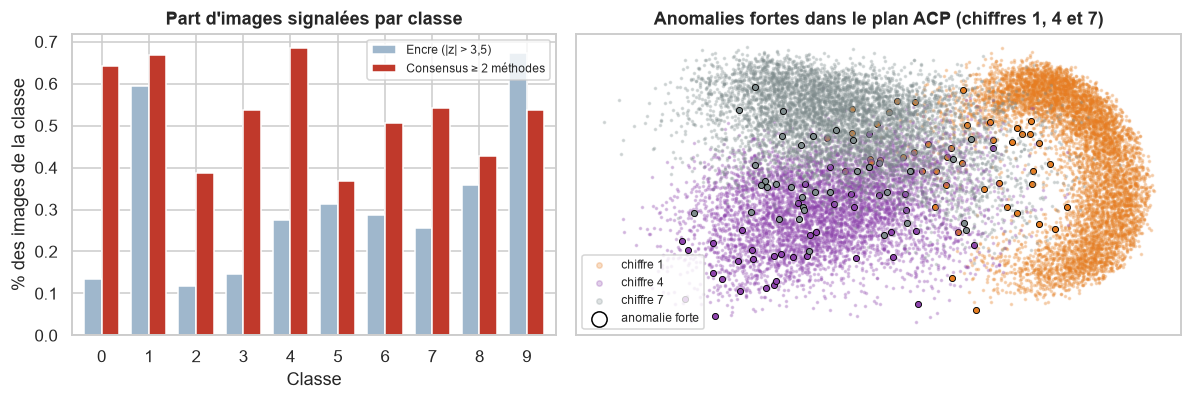

In [5]:
# (gauche) part d'images signalées par classe ; (droite) position des anomalies fortes dans le 1er plan ACP de 3 classes
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})
part = pd.DataFrame({"Encre (|z| > 3,5)": flag_uni, "Consensus ≥ 2 méthodes": forte, "classe": y_train})     .groupby("classe").mean() * 100
part.plot.bar(ax=axes[0], color=["#9fb7cc", "#c0392b"], width=0.75, edgecolor="white")
axes[0].set_xlabel("Classe"); axes[0].set_ylabel("% des images de la classe"); axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(fontsize=8); axes[0].set_title("Part d'images signalées par classe")

pal = {1: "#e67e22", 4: "#8e44ad", 7: "#7f8c8d"}
p2 = PCA(2, random_state=SEED).fit(Z[np.isin(y_train, list(pal))])
for c, col in pal.items():
    m = (y_train == c)
    P = p2.transform(Z[m])
    axes[1].scatter(P[~forte[m], 0], P[~forte[m], 1], s=2, alpha=0.25, color=col, label=f"chiffre {c}")
    axes[1].scatter(P[forte[m], 0], P[forte[m], 1], s=16, color=col, edgecolor="black", lw=0.6)
axes[1].scatter([], [], s=16, color="white", edgecolor="black", label="anomalie forte")
axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].legend(fontsize=8, markerscale=2.5, loc="best")
axes[1].set_title("Anomalies fortes dans le plan ACP (chiffres 1, 4 et 7)")
plt.tight_layout(); savefig("fig6_1_scores"); plt.show()

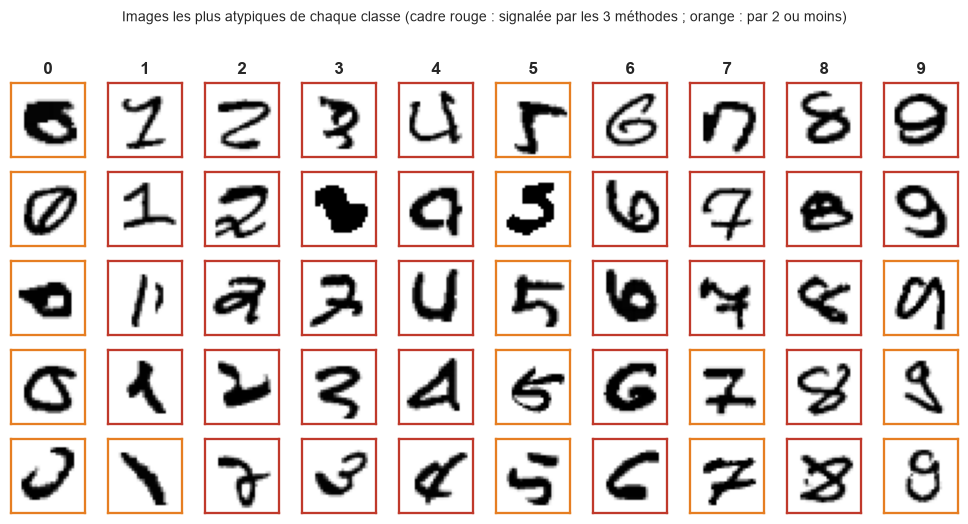

In [6]:
# Galerie : les 5 images les plus anormales de chaque classe (score agrégé), une colonne par classe
N = 5
fig, axes = plt.subplots(N, 10, figsize=(10 * 0.9, N * 0.95))
for c in range(10):
    m = np.flatnonzero(y_train == c)
    top = m[np.argsort(-score_global[m])[:N]]
    for j, i in enumerate(top):
        ax = axes[j, c]; ax.imshow(X_train[i], cmap="gray_r"); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_edgecolor("#c0392b" if nb_methodes[i] == 3 else "#e67e22"); sp.set_linewidth(1.5)
        if j == 0:
            ax.set_title(str(c), fontsize=11, fontweight="bold")
fig.suptitle("Images les plus atypiques de chaque classe (cadre rouge : signalée par les 3 méthodes ; orange : par 2 ou moins)",
             y=1.0, fontsize=9)
plt.tight_layout(); savefig("fig6_2_galerie_atypiques"); plt.show()

## 6.3 Détection d'étiquettes probablement erronées

Une image atypique n'est pas forcément mal étiquetée. Pour repérer les **erreurs d'étiquetage**, on estime pour chaque image la probabilité de son étiquette **sans qu'elle ait servi à l'apprentissage** :
probabilités obtenues par **validation croisée stratifiée à 5 plis** (`cross_val_predict`) avec **deux modèles de natures différentes**, dans l'espace ACP-50 :

* un **KNN** à 10 voisins (modèle local, fondé sur les distances) ;
* un **perceptron multicouche** (une couche cachée de 256 neurones ; modèle global).

Une étiquette est jugée **suspecte** si, pour les deux modèles, la probabilité de l'étiquette donnée est quasi nulle (KNN : aucun des 10 voisins ; MLP : < 5 %) **et** s'ils s'accordent avec confiance (≥ 80 %) sur une **même** autre classe.
Exiger l'accord de deux modèles différents limite les faux positifs : un chiffre simplement mal écrit trompe rarement les deux de la même façon.

In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
idx = np.arange(len(X))
t0 = time.time()
proba_knn = cross_val_predict(KNeighborsClassifier(n_neighbors=10, n_jobs=-1), Z, y_train, cv=cv,
                              method="predict_proba")
t1 = time.time()
mlp = MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-4, max_iter=60, early_stopping=True, random_state=SEED)
proba_mlp = cross_val_predict(mlp, Z, y_train, cv=cv, method="predict_proba", n_jobs=-1)
print(f"KNN : {t1 - t0:.0f} s ; MLP : {time.time() - t1:.0f} s")

pred_knn, pred_mlp = proba_knn.argmax(1), proba_mlp.argmax(1)
susp_knn = (proba_knn[idx, y_train] == 0) & (proba_knn.max(1) >= 0.8)
susp_mlp = (proba_mlp[idx, y_train] < 0.05) & (proba_mlp.max(1) >= 0.8)
suspect = susp_knn & susp_mlp & (pred_knn == pred_mlp)
pred = pred_mlp
p_max = proba_mlp.max(1)
print(f"Accuracy en validation croisée : KNN = {(pred_knn == y_train).mean():.4f} ; MLP = {(pred_mlp == y_train).mean():.4f}")
print(f"Suspects : KNN seul = {susp_knn.sum()}, MLP seul = {susp_mlp.sum()}, accord des deux = {suspect.sum()}")

CH.update({
    "knn_cv_accuracy_pct": pct((pred_knn == y_train).mean()),
    "mlp_cv_accuracy_pct": pct((pred_mlp == y_train).mean()),
    "suspects_knn_n": int(susp_knn.sum()), "suspects_mlp_n": int(susp_mlp.sum()),
    "suspects_n": int(suspect.sum()), "suspects_pct": pct(suspect.mean(), 3),
    "suspects_aussi_forte_n": int((suspect & forte).sum()),
})
paires = pd.Series([f"{a} → {b}" for a, b in zip(y_train[suspect], pred[suspect])]).value_counts()
CH["suspects_paires"] = [f"{k} ({v})" for k, v in paires.head(4).items()]

tab_susp = pd.DataFrame({"indice": np.flatnonzero(suspect), "label_donne": y_train[suspect],
                         "label_predit": pred[suspect], "proba_predit": p_max[suspect],
                         "anomalie_forte": forte[suspect]}).sort_values("proba_predit", ascending=False)
tab_susp.to_csv(RES / "t6_2_etiquettes_suspectes.csv", index=False)
print(f"{suspect.sum()} étiquettes suspectes ({pct(suspect.mean(), 3)} %) ; confusions les plus fréquentes : {', '.join(CH['suspects_paires'])}")
paires.head(10)

KNN : 8 s ; MLP : 28 s
Accuracy en validation croisée : KNN = 0.9735 ; MLP = 0.9794
Suspects : KNN seul = 191, MLP seul = 302, accord des deux = 78
78 étiquettes suspectes (0.13 %) ; confusions les plus fréquentes : 3 → 7 (4), 8 → 1 (4), 9 → 7 (4), 8 → 9 (3)


3 → 7    4
8 → 1    4
9 → 7    4
8 → 9    3
2 → 0    3
3 → 2    3
5 → 6    3
2 → 7    3
7 → 2    3
8 → 5    2
Name: count, dtype: int64

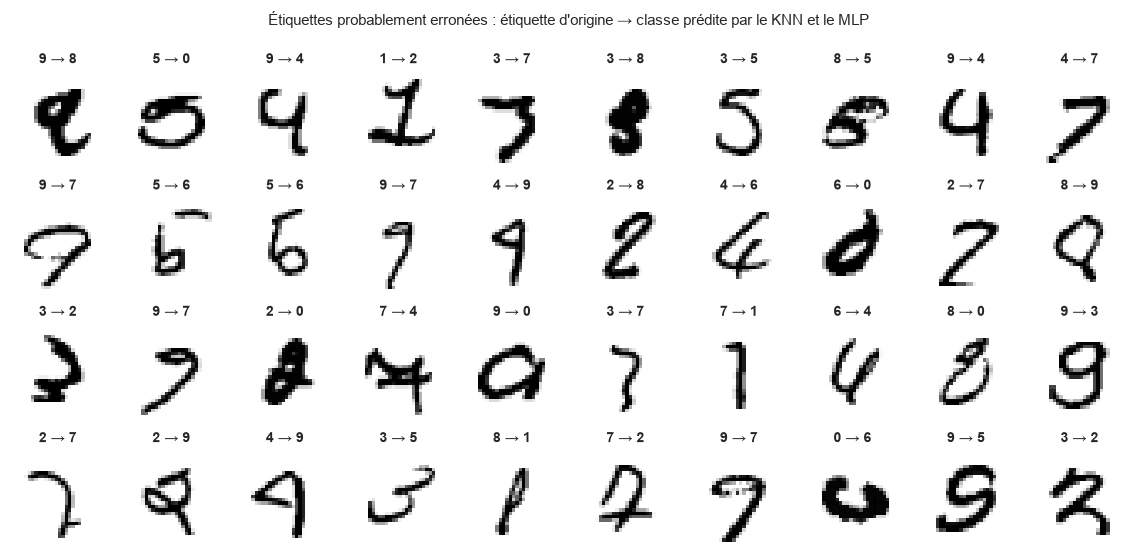

In [8]:
# Galerie des étiquettes suspectes (les plus « sûres » d'abord)
n = min(40, len(tab_susp))
cols = 10; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.05, rows * 1.3))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, r) in zip(axes.ravel(), tab_susp.head(n).iterrows()):
    ax.imshow(X_train[r.indice], cmap="gray_r")
    ax.set_title(f"{r.label_donne} → {r.label_predit}", fontsize=9)
fig.suptitle("Étiquettes probablement erronées : étiquette d'origine → classe prédite par le KNN et le MLP", fontsize=10)
plt.tight_layout(); savefig("fig6_3_etiquettes_suspectes"); plt.show()

## 6.4 Décision : modifier ou non le jeu de données ?

* **Images atypiques (consensus) : conservées.** Elles correspondent à des écritures réelles (styles rares, traits épais, inclinaisons fortes) que le modèle rencontrera aussi en test ; les supprimer rendrait le modèle moins robuste et optimiserait artificiellement les scores.
* **Étiquettes suspectes : retirées du jeu d'apprentissage** après vérification visuelle (galerie ci-dessus). Elles enseignent au modèle une association fausse ; leur nombre est très faible, donc leur retrait ne modifie pas l'équilibre des classes.
* **Jeu de test : inchangé**, pour que les performances restent comparables à celles de la littérature (partie 2).

Le fichier `resultats/t6_3_indices_train_retires.csv` liste les images retirées ; la partie 8 l'utilisera (et pourra comparer les performances avec / sans retrait).

In [9]:
retires = np.flatnonzero(suspect)
pd.DataFrame({"indice": retires, "label_donne": y_train[retires], "label_predit": pred[retires]}) \
  .to_csv(RES / "t6_3_indices_train_retires.csv", index=False)
garde = np.setdiff1d(np.arange(len(X)), retires)
eq = pd.Series(y_train[garde]).value_counts(normalize=True).sort_index() * 100
CH.update({"n_train_apres": int(len(garde)),
           "pct_min_apres": round(float(eq.min()), 1), "pct_max_apres": round(float(eq.max()), 1),
           "date_execution": time.strftime("%Y-%m-%d")})

# export des scores pour réutilisation (partie 8 / annexes)
pd.DataFrame({"indice": np.arange(len(X)), "label": y_train, "z_encre": z.round(2),
              "score_reconstruction": score["reconstruction"].round(3), "score_iforest": score["iforest"].round(4),
              "score_lof": score["lof"].round(3), "nb_methodes": nb_methodes, "anomalie_forte": forte,
              "etiquette_suspecte": suspect}).to_csv(RES / "t6_4_scores_anomalies.csv", index=False)
(RES / "chiffres_cles_p6.json").write_text(json.dumps(CH, indent=2, ensure_ascii=False), encoding="utf-8")
CH

{'uni_pct': 0.32,
 'uni_n': 191,
 'uni_haut_pct': 0.32,
 'uni_bas_pct': 0.0,
 'uni_classe_max': 9,
 'uni_classe_max_pct': 0.67,
 'pca50_var_pct': 82.5,
 'consensus_n': 320,
 'consensus_pct': 0.53,
 'trois_methodes_n': 44,
 'jaccard_rec_iso': 0.22,
 'jaccard_rec_lof': 0.12,
 'jaccard_iso_lof': 0.06,
 'part_forte_aussi_univ_pct': 10.0,
 'consensus_classe_max': 4,
 'consensus_classe_max_pct': 0.68,
 'consensus_classe_min': 5,
 'consensus_classe_min_pct': 0.37,
 'encre_med_forte': 141.7,
 'encre_med_normale': 99.7,
 'knn_cv_accuracy_pct': 97.35,
 'mlp_cv_accuracy_pct': 97.94,
 'suspects_knn_n': 191,
 'suspects_mlp_n': 302,
 'suspects_n': 78,
 'suspects_pct': 0.13,
 'suspects_aussi_forte_n': 14,
 'suspects_paires': ['3 → 7 (4)', '8 → 1 (4)', '9 → 7 (4)', '8 → 9 (3)'],
 'n_train_apres': 59922,
 'pct_min_apres': 9.0,
 'pct_max_apres': 11.2,
 'date_execution': '2026-10-16'}